# Trabajo 15: Descarga y Preparación de Datasets (GAVD y CASIA-B)

Este cuaderno automatiza la descarga y estructuración de los dos conjuntos de datos de vídeo necesarios para el sistema de detección de episodios de bloqueo de la marcha (*Freezing of Gait*):
1. **GAVD (*Gait Abnormality in Video Dataset*):** Descarga las anotaciones clínicas abiertas y recorta automáticamente los clips de vídeo relevantes (marcha parkinsoniana y anomalías).
2. **CASIA-B (*Multi-View Gait Dataset*):** Descarga las secuencias de marcha normal desde 11 ángulos de cámara distintos (`0°` a `180°`) para entrenar la clase negativa (marcha/parada normal) y evaluar la robustez frente a cambios de perspectiva.

### Estructura de carpetas generada
```text
data/
├── raw/
│   ├── gavd/
│   │   ├── annotations/      # CSVs originales con bounding boxes y etiquetas
│   │   └── clips/            # Vídeos recortados listos para extracción de pose
│   └── casia_b/              # Secuencias multi-vista organizadas
└── metadata/                 # Índices unificados (metadata_gavd.csv y metadata_casiab.csv)
```

In [1]:
# Instalación de dependencias multiplataforma
%pip install -q requests pandas yt-dlp opencv-python tqdm kagglehub huggingface_hub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
%pip install -q pyarrow huggingface_hub matplotlib 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import shutil
import zipfile
from pathlib import Path
import requests
import pandas as pd
import cv2
from tqdm.auto import tqdm
import yt_dlp

# Configuración de rutas base
BASE_DIR = Path('data')
GAVD_ANN_DIR = BASE_DIR / 'raw' / 'gavd' / 'annotations'
GAVD_CLIPS_DIR = BASE_DIR / 'raw' / 'gavd' / 'clips'
CASIA_DIR = BASE_DIR / 'raw' / 'casia_b'
META_DIR = BASE_DIR / 'metadata'

for folder in [GAVD_ANN_DIR, GAVD_CLIPS_DIR, CASIA_DIR, META_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print(f'Estructura de directorios lista en: {BASE_DIR.resolve()}')

d:\universidad\cuarto\primer_cuatri\entornos_inteligentes\trabajo_final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Estructura de directorios lista en: D:\universidad\cuarto\primer_cuatri\entornos_inteligentes\trabajo_final\data


## 1. Descarga de GAVD (*Gait Abnormality in Video Dataset*)

El siguiente bloque localiza automáticamente los archivos de anotaciones `.csv` de GAVD en GitHub, los descarga y filtra las secuencias correspondientes a marcha parkinsoniana (`parkinsons`) y marcha normal de control (`normal`).

In [3]:
def descargar_anotaciones_gavd(destino: Path):
    """Busca y descarga los CSV de anotaciones de GAVD desde repositorios públicos."""
    print('Buscando repositorio oficial de GAVD en GitHub...')
    api_url = 'https://api.github.com/search/repositories?q=GAVD+Gait+Abnormality+in:name,description'
    resp = requests.get(api_url, timeout=15)
    resp.raise_for_status()
    items = resp.json().get('items', [])

    csv_urls = []
    for repo in items[:3]:
        full_name = repo['full_name']
        default_branch = repo.get('default_branch', 'main')
        tree_url = f'https://api.github.com/repos/{full_name}/git/trees/{default_branch}?recursive=1'
        tree_resp = requests.get(tree_url, timeout=15)
        if tree_resp.status_code == 200:
            for node in tree_resp.json().get('tree', []):
                if node['path'].endswith('.csv') and ('GAVD' in node['path'] or 'annotation' in node['path'].lower()):
                    raw_url = f"https://raw.githubusercontent.com/{full_name}/{default_branch}/{node['path']}"
                    csv_urls.append((Path(node['path']).name, raw_url))
        if csv_urls:
            print(f'Repositorio localizado: {full_name} ({len(csv_urls)} archivos CSV)')
            break

    if not csv_urls:
        raise RuntimeError(
            'No se encontraron CSVs automáticamente. Descárgalos manualmente desde GitHub/HuggingFace '
            'y colócalos en data/raw/gavd/annotations/'
        )

    archivos_locales = []
    for nombre, url in csv_urls:
        ruta_salida = destino / nombre
        if not ruta_salida.exists():
            r = requests.get(url, timeout=30)
            r.raise_for_status()
            ruta_salida.write_bytes(r.content)
        archivos_locales.append(ruta_salida)
        print(f'  -> Guardado: {ruta_salida.name}')

    return archivos_locales

csv_files = descargar_anotaciones_gavd(GAVD_ANN_DIR)
df_gavd = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
print(f'Total de fotogramas anotados en GAVD: {len(df_gavd)}')
if 'gait_pat' in df_gavd.columns:
    print('\nDistribución de patrones de marcha disponibles:')
    print(df_gavd['gait_pat'].value_counts())

Buscando repositorio oficial de GAVD en GitHub...
Repositorio localizado: Rahmyyy/GAVD (5 archivos CSV)
  -> Guardado: GAVD_Clinical_Annotations_1.csv
  -> Guardado: GAVD_Clinical_Annotations_2.csv
  -> Guardado: GAVD_Clinical_Annotations_3.csv
  -> Guardado: GAVD_Clinical_Annotations_4.csv
  -> Guardado: GAVD_Clinical_Annotations_5.csv


C:\Users\Alejandro López\AppData\Local\Temp\ipykernel_26040\781903927.py:43: DtypeWarning: Columns (3: gait_event) have mixed types. Specify dtype option on import or set low_memory=False.
  df_gavd = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)


Total de fotogramas anotados en GAVD: 458116

Distribución de patrones de marcha disponibles:
gait_pat
abnormal          216492
exercise           54941
normal             41340
myopathic          34595
stroke             33934
cerebral palsy     20346
prosthetic         17999
style              13571
parkinsons         10426
inebriated          7007
antalgic            6556
pregnant             909
Name: count, dtype: int64


In [4]:
# Parámetros de descarga de clips de GAVD
# Sube MAX_CLIPS_POR_CLASE a None cuando quieras descargar el dataset completo
MAX_CLIPS_POR_CLASE = 25
CLASES_OBJETIVO = ['parkinsons', 'normal']

def descargar_y_recortar_gavd(df: pd.DataFrame, clips_dir: Path, max_clips=25):
    temp_dir = clips_dir / '_temp_full_videos'
    temp_dir.mkdir(exist_ok=True)

    # Agrupar por secuencia para obtener URL y rango de fotogramas
    df_filtrado = df[df['gait_pat'].str.lower().isin(CLASES_OBJETIVO)].copy()
    secuencias = []

    for seq_id, grupo in df_filtrado.groupby('seq'):
        url = grupo['url'].iloc[0]
        patron = grupo['gait_pat'].iloc[0].lower()
        f_inicio = int(grupo['frame_num'].min())
        f_fin = int(grupo['frame_num'].max())
        secuencias.append({
            'seq_id': seq_id,
            'gait_pat': patron,
            'url': url,
            'frame_start': f_inicio,
            'frame_end': f_fin
        })

    df_seqs = pd.DataFrame(secuencias)
    if max_clips is not None:
        df_seqs = df_seqs.groupby('gait_pat').head(max_clips).reset_index(drop=True)

    ydl_opts = {
        'format': 'bestvideo[height<=720][ext=mp4]/best[height<=720][ext=mp4]/best',
        'outtmpl': str(temp_dir / '%(id)s.%(ext)s'),
        'quiet': True,
        'no_warnings': True
    }

    registros_validos = []
    with yt_dlp.YoutubeDL(ydl_opts) as ydl:
        for _, row in tqdm(df_seqs.iterrows(), total=len(df_seqs), desc='Procesando clips GAVD'):
            clip_path = clips_dir / f"{row['gait_pat']}_{row['seq_id']}.mp4"
            if clip_path.exists():
                registros_validos.append({**row.to_dict(), 'clip_path': str(clip_path)})
                continue

            try:
                info = ydl.extract_info(row['url'], download=True)
                video_completo = Path(ydl.prepare_filename(info))

                cap = cv2.VideoCapture(str(video_completo))
                fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
                w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
                h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

                fourcc = cv2.VideoWriter_fourcc(*'mp4v')
                out = cv2.VideoWriter(str(clip_path), fourcc, fps, (w, h))

                cap.set(cv2.CAP_PROP_POS_FRAMES, row['frame_start'])
                for _ in range(row['frame_start'], row['frame_end'] + 1):
                    ret, frame = cap.read()
                    if not ret:
                        break
                    out.write(frame)

                cap.release()
                out.release()

                if clip_path.exists() and clip_path.stat().st_size > 1024:
                    registros_validos.append({**row.to_dict(), 'clip_path': str(clip_path)})
            except Exception:
                # Algunos vídeos fuente pueden haber sido retirados de la plataforma
                continue

    shutil.rmtree(temp_dir, ignore_errors=True)
    meta_df = pd.DataFrame(registros_validos)
    meta_df.to_csv(META_DIR / 'metadata_gavd.csv', index=False)
    print(f'Clips GAVD descargados y recortados con éxito: {len(meta_df)}')
    return meta_df

meta_gavd = descargar_y_recortar_gavd(df_gavd, GAVD_CLIPS_DIR, max_clips=MAX_CLIPS_POR_CLASE)

Procesando clips GAVD:   0%|          | 0/50 [00:00<?, ?it/s]

Procesando clips GAVD:   2%|▏         | 1/50 [00:10<08:28, 10.38s/it]

Procesando clips GAVD:   4%|▍         | 2/50 [00:14<05:16,  6.59s/it]

Procesando clips GAVD:   6%|▌         | 3/50 [00:23<06:15,  7.99s/it]

Procesando clips GAVD:   8%|▊         | 4/50 [00:25<04:12,  5.50s/it]

Procesando clips GAVD:  10%|█         | 5/50 [00:27<03:04,  4.10s/it]

... (33 outputs left out)

Procesando clips GAVD:  96%|█████████▌| 48/50 [02:22<00:03,  1.63s/it]

Procesando clips GAVD:  98%|█████████▊| 49/50 [02:24<00:01,  1.59s/it]

Procesando clips GAVD: 100%|██████████| 50/50 [02:25<00:00,  2.91s/it]

Clips GAVD descargados y recortados con éxito: 41


## 2. Descarga de CASIA-B (*Multi-View Gait Dataset*)

Utilizamos `kagglehub` para descargar CASIA-B sin esperas de aprobación institucional. Si es la primera vez que usas Kaggle desde Python, asegúrate de tener tu archivo `kaggle.json` en `~/.kaggle/kaggle.json` (Linux) o `C:\Users\<Usuario>\.kaggle\kaggle.json` (Windows), o introduce tus credenciales cuando te las solicite la librería.

In [16]:
import re
import shutil
import zipfile
from pathlib import Path
import cv2
import pandas as pd
import requests
import urllib3
from tqdm.auto import tqdm

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

BASE_DIR = Path('data')
META_DIR = BASE_DIR / 'metadata'
URFALL_CLIPS_DIR = BASE_DIR / 'raw' / 'ur_fall' / 'clips'
META_DIR.mkdir(parents=True, exist_ok=True)
URFALL_CLIPS_DIR.mkdir(parents=True, exist_ok=True)

MAX_ADL = 25    # Actividades diarias normales (caminar, detenerse, sentarse)
MAX_FALL = 10   # Caídas y pérdida de equilibrio

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
    )
}

def orden_natural(path_obj: Path):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r'(\d+)', path_obj.name)]

def compilar_frames_a_mp4(carpeta_frames: Path, salida_mp4: Path, fps: float = 30.0) -> bool:
    frames = sorted(
        [p for p in carpeta_frames.rglob('*') if p.is_file() and p.suffix.lower() in ('.png', '.jpg', '.jpeg')],
        key=orden_natural
    )
    if len(frames) < 10:
        return False

    first_img = cv2.imread(str(frames[0]))
    if first_img is None:
        return False

    h, w = first_img.shape[:2]
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(str(salida_mp4), fourcc, fps, (w, h))
    for f_path in frames:
        img = cv2.imread(str(f_path))
        if img is not None:
            out.write(img)
    out.release()
    return salida_mp4.exists() and salida_mp4.stat().st_size > 1024

def comprobar_servidor_ur() -> bool:
    test_url = "http://fenix.ur.edu.pl/~mkepski/ds/data/adl-01-cam0-rgb.zip"
    try:
        with requests.get(test_url, headers=HEADERS, timeout=15, verify=False, stream=True) as r:
            print(f"Respuesta servidor UR Fall: HTTP {r.status_code}")
            return r.status_code == 200
    except Exception as e:
        print(f"Servidor UR Fall inaccesible ({type(e).__name__}: {e})")
        return False

def descargar_desde_ur_directo(clips_dir: Path, max_adl: int, max_fall: int) -> list[dict]:
    seleccion = (
        [('adl', f"adl-{i:02d}", f"http://fenix.ur.edu.pl/~mkepski/ds/data/adl-{i:02d}-cam0-rgb.zip") for i in range(1, max_adl + 1)] +
        [('fall', f"fall-{i:02d}", f"http://fenix.ur.edu.pl/~mkepski/ds/data/fall-{i:02d}-cam0-rgb.zip") for i in range(1, max_fall + 1)]
    )

    temp_dir = clips_dir / '_temp_extract'
    temp_dir.mkdir(exist_ok=True)
    registros = []

    for categoria, seq_id, url in tqdm(seleccion, desc="Descargando UR Fall (servidor oficial)"):
        mp4_path = clips_dir / f"{seq_id}.mp4"
        if not mp4_path.exists():
            zip_path = temp_dir / f"{seq_id}.zip"
            extract_folder = temp_dir / seq_id
            try:
                r = requests.get(url, headers=HEADERS, timeout=60, verify=False)
                if r.status_code != 200:
                    continue
                zip_path.write_bytes(r.content)
                with zipfile.ZipFile(zip_path, 'r') as zf:
                    zf.extractall(extract_folder)
                compilar_frames_a_mp4(extract_folder, mp4_path)
            except Exception:
                continue
            finally:
                if zip_path.exists():
                    zip_path.unlink()
                shutil.rmtree(extract_folder, ignore_errors=True)

        if mp4_path.exists() and mp4_path.stat().st_size > 1024:
            cap = cv2.VideoCapture(str(mp4_path))
            num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            cap.release()
            registros.append({
                'seq_id': seq_id,
                'category': categoria,
                'num_frames': num_frames,
                'fps': 30.0,
                'clip_path': str(mp4_path)
            })

    shutil.rmtree(temp_dir, ignore_errors=True)
    return registros

def descargar_respaldo_kaggle(clips_dir: Path, max_total: int = 35) -> list[dict]:
    import kagglehub
    from kagglesdk import KaggleClient
    from kagglesdk.datasets.types.dataset_api_service import ApiListDatasetsRequest

    print("\nActivando respaldo automático en Kaggle (UR-Fall / UP-Fall)...")
    client = KaggleClient()
    slug_elegido = None

    for termino in ['ur-fall', 'ur fall detection', 'up-fall']:
        req = ApiListDatasetsRequest()
        req.search = termino
        res = client.datasets.dataset_api_client.list_datasets(req)
        for ds in res.datasets:
            ref = getattr(ds, 'ref', '')
            size = getattr(ds, 'total_bytes', 0) or 0
            # Filtrar datasets con multimedia real (> 50 MB)
            if size > 50 * 1024 * 1024:
                slug_elegido = ref
                print(f"Dataset encontrado en Kaggle: {slug_elegido} ({size / (1024**2):.1f} MB)")
                break
        if slug_elegido:
            break

    if not slug_elegido:
        raise RuntimeError("No se encontró un dataset multimedia alternativo en Kaggle.")

    cache_path = Path(kagglehub.dataset_download(slug_elegido))
    print(f"Descarga en caché completada: {cache_path}")

    registros = []
    # 1. Si trae vídeos .mp4 / .avi directos
    videos = sorted([p for p in cache_path.rglob('*') if p.is_file() and p.suffix.lower() in ('.mp4', '.avi')])
    if videos:
        for idx, vid in enumerate(tqdm(videos[:max_total], desc="Copiando vídeos de control")):
            cat = 'fall' if 'fall' in str(vid).lower() else 'adl'
            seq_id = f"{cat}-{idx+1:02d}"
            dst = clips_dir / f"{seq_id}{vid.suffix.lower()}"
            if not dst.exists():
                shutil.copyfile(vid, dst)
            cap = cv2.VideoCapture(str(dst))
            num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
            cap.release()
            registros.append({
                'seq_id': seq_id,
                'category': cat,
                'num_frames': num_frames,
                'fps': fps,
                'clip_path': str(dst)
            })
        return registros

    # 2. Si trae carpetas de fotogramas .png/.jpg (estructura estándar UR-Fall)
    carpetas_con_img = sorted({
        p.parent for p in cache_path.rglob('*')
        if p.is_file() and p.suffix.lower() in ('.png', '.jpg') and 'depth' not in str(p).lower()
    })
    for idx, folder in enumerate(tqdm(carpetas_con_img[:max_total], desc="Compilando secuencias a MP4")):
        cat = 'fall' if 'fall' in folder.name.lower() else 'adl'
        seq_id = f"{cat}-{idx+1:02d}"
        dst = clips_dir / f"{seq_id}.mp4"
        if dst.exists() or compilar_frames_a_mp4(folder, dst):
            cap = cv2.VideoCapture(str(dst))
            num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            cap.release()
            registros.append({
                'seq_id': seq_id,
                'category': cat,
                'num_frames': num_frames,
                'fps': 30.0,
                'clip_path': str(dst)
            })

    return registros

# Ejecución con fallback automático
if comprobar_servidor_ur():
    registros_ur = descargar_desde_ur_directo(URFALL_CLIPS_DIR, MAX_ADL, MAX_FALL)
else:
    registros_ur = descargar_respaldo_kaggle(URFALL_CLIPS_DIR, max_total=MAX_ADL + MAX_FALL)

df_urfall = pd.DataFrame(registros_ur)
df_urfall.to_csv(META_DIR / 'metadata_urfall.csv', index=False)

print("\n--- RESUMEN FINAL DE DATASETS LISTOS ---")
for nombre_meta in ['metadata_gavd.csv', 'metadata_urfall.csv']:
    ruta = META_DIR / nombre_meta
    if ruta.exists():
        df_tmp = pd.read_csv(ruta)
        print(f"[OK] {nombre_meta}: {len(df_tmp)} vídeos preparados.")

Respuesta servidor UR Fall: HTTP 200


Descargando UR Fall (servidor oficial): 100%|██████████| 35/35 [08:03<00:00, 13.81s/it]



--- RESUMEN FINAL DE DATASETS LISTOS ---
[OK] metadata_gavd.csv: 41 vídeos preparados.
[OK] metadata_urfall.csv: 35 vídeos preparados.


## 3. Verificación final del entorno de datos

Comprueba que ambos índices CSV metadata_gavd.csv y metadata_casiab.csv contienen rutas válidas antes de pasar al cuaderno de extracción de puntos clave con YOLOv8-Pose.

In [17]:
for nombre_meta in ['metadata_gavd.csv', 'metadata_urfall.csv']:
    ruta = META_DIR / nombre_meta
    if ruta.exists():
        df_tmp = pd.read_csv(ruta)
        print(f'[OK] {nombre_meta}: {len(df_tmp)} secuencias registradas.')
    else:
        print(f'[PENDIENTE] {nombre_meta} no encontrado.')

[OK] metadata_gavd.csv: 41 secuencias registradas.
[OK] metadata_urfall.csv: 35 secuencias registradas.


=== GAVD: 41/41 vídeos válidos ===
Resolución típica: 1280x480 | Duración media: 8.05 s | Frames totales: 8829

=== UR Fall: 35/35 vídeos válidos ===
Resolución típica: 640x480 | Duración media: 6.45 s | Frames totales: 6774



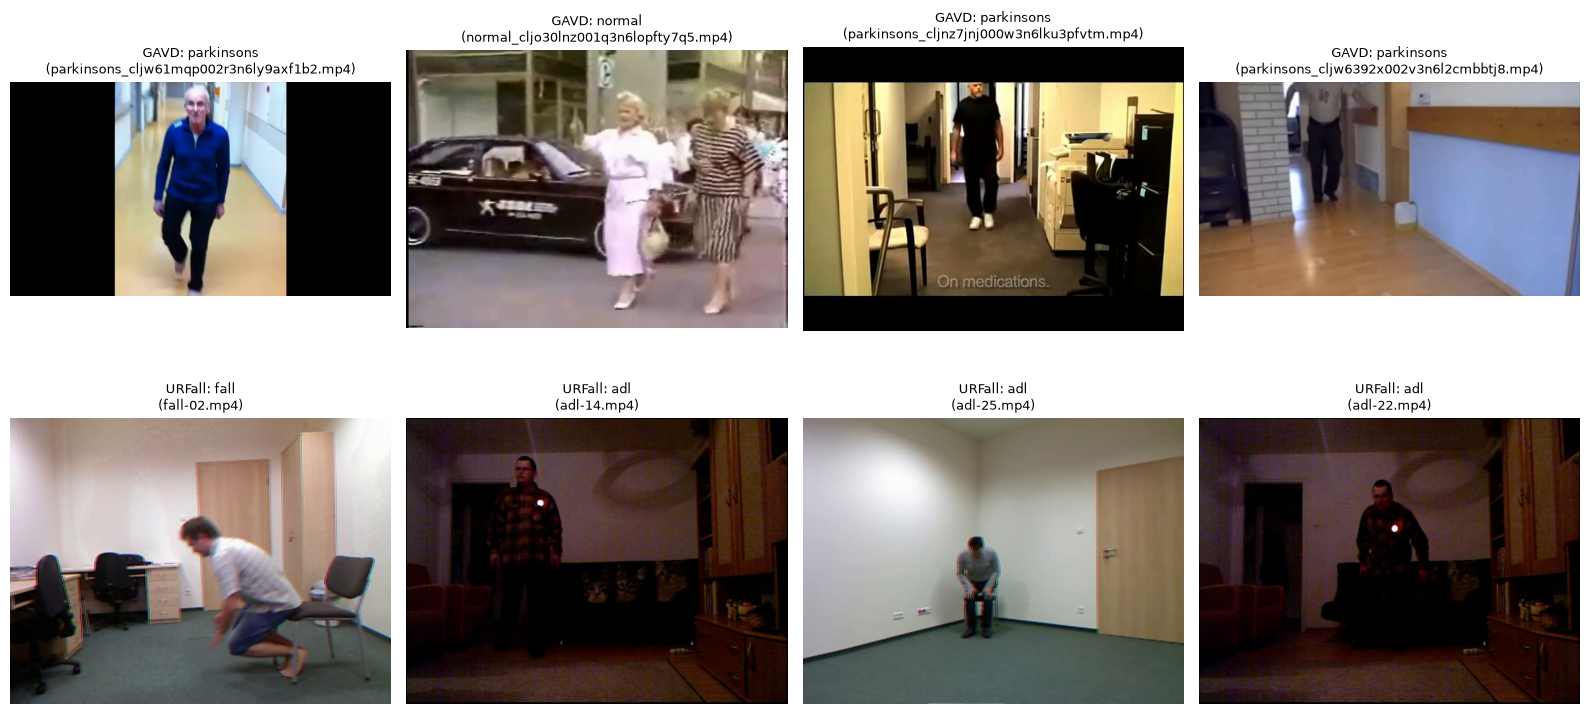

In [20]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import pandas as pd

META_DIR = Path('data/metadata')
df_gavd = pd.read_csv(META_DIR / 'metadata_gavd.csv')
df_urfall = pd.read_csv(META_DIR / 'metadata_urfall.csv')

def auditar_videos(df: pd.DataFrame, nombre: str) -> pd.DataFrame:
    col_ruta = 'clip_path' if 'clip_path' in df.columns else 'file_path'
    stats = []
    for _, row in df.iterrows():
        p = Path(row[col_ruta])
        if not p.exists():
            stats.append({'ok': False, 'w': 0, 'h': 0, 'fps': 0, 'frames': 0, 'seg': 0})
            continue
        cap = cv2.VideoCapture(str(p))
        w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
        frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.release()
        stats.append({
            'ok': frames > 5 and w > 0,
            'w': w,
            'h': h,
            'fps': round(fps, 1),
            'frames': frames,
            'seg': round(frames / fps, 2)
        })
    df_stats = pd.concat([df.reset_index(drop=True), pd.DataFrame(stats)], axis=1)
    validos = df_stats['ok'].sum()
    print(f"=== {nombre}: {validos}/{len(df_stats)} vídeos válidos ===")
    print(f"Resolución típica: {df_stats['w'].mode()[0]}x{df_stats['h'].mode()[0]} | "
          f"Duración media: {df_stats['seg'].mean():.2f} s | "
          f"Frames totales: {df_stats['frames'].sum()}\n")
    return df_stats

gavd_ok = auditar_videos(df_gavd, "GAVD")
urfall_ok = auditar_videos(df_urfall, "UR Fall")

# Mostrar cuadrícula 2x4 con fotogramas centrales
muestras = []
for _, r in gavd_ok[gavd_ok['ok']].sample(min(4, len(gavd_ok)), random_state=42).iterrows():
    muestras.append((f"GAVD: {r.get('gait_pat', 'gavd')}", r['clip_path']))
for _, r in urfall_ok[urfall_ok['ok']].sample(min(4, len(urfall_ok)), random_state=42).iterrows():
    muestras.append((f"URFall: {r.get('category', 'urfall')}", r['clip_path']))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (titulo, ruta) in zip(axes.flat, muestras):
    cap = cv2.VideoCapture(str(ruta))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, total // 2)
    ret, frame = cap.read()
    cap.release()
    if ret:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{titulo}\n({Path(ruta).name})", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [21]:
%pip install -q ultralytics

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


WARNING Ultralytics settings updated to the latest schema. Existing values were preserved where possible. 
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Alejandro López\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ejecutando YOLOv8-Pose en dispositivo: CPU
[parkinsons_cljan9b4p00043n6ligceanyp.mp4] -> Persona detectada: 100.0% | Tobillos visibles: 100.0% | Guardado en: data\debug_samples\test_pose_gavd.mp4
[adl-01.mp4] -> Persona detectada: 95.3% | Tobillos visibles: 94.0% | Guardado en: data\debug_samples\test_pose_urfall.mp4


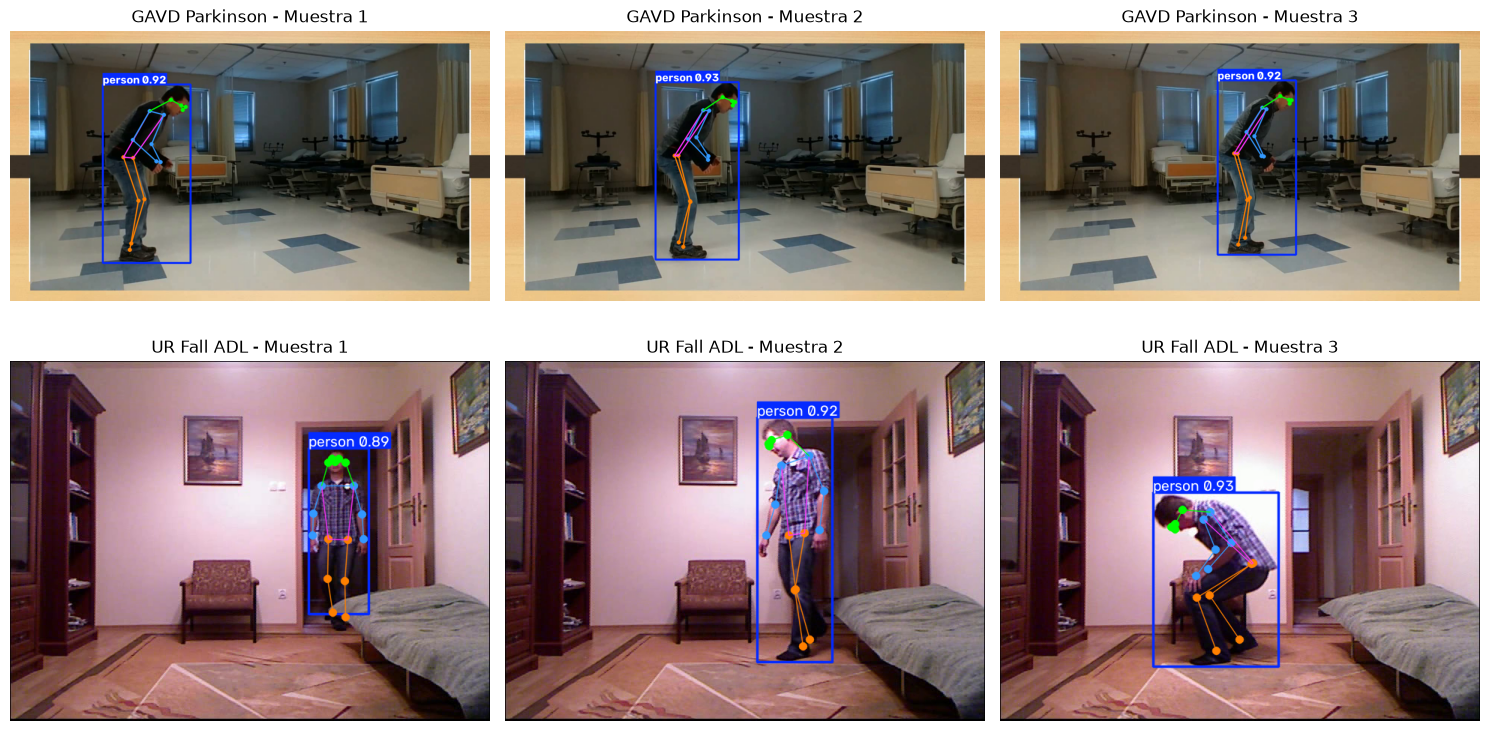

In [22]:


from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from ultralytics import YOLO

DEBUG_DIR = Path('data/debug_samples')
DEBUG_DIR.mkdir(parents=True, exist_ok=True)

device = 0 if torch.cuda.is_available() else 'cpu'
print(f"Ejecutando YOLOv8-Pose en dispositivo: {'GPU CUDA' if device == 0 else 'CPU'}")

# Descarga automáticamente los pesos ligeros (~6 MB) en la primera ejecución
modelo_pose = YOLO('yolov8n-pose.pt')

def probar_pose_en_video(ruta_video: str, nombre_salida: str):
    cap = cv2.VideoCapture(str(ruta_video))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    ruta_mp4_out = DEBUG_DIR / nombre_salida
    out = cv2.VideoWriter(str(ruta_mp4_out), cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

    frames_con_persona = 0
    frames_con_tobillos = 0
    fotogramas_muestra = []
    indices_muestra = {total_frames // 4, total_frames // 2, (3 * total_frames) // 4}

    idx = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        results = modelo_pose.predict(frame, device=device, verbose=False, conf=0.4)
        res = results[0]
        frame_anotado = res.plot()  # Dibuja bounding box y esqueleto COCO-17

        if res.keypoints is not None and len(res.keypoints.conf) > 0:
            frames_con_persona += 1
            # Tomar la persona principal (índice 0) y revisar confianza de tobillos (15 y 16)
            confs = res.keypoints.conf[0].cpu().numpy()
            if confs[15] > 0.4 and confs[16] > 0.4:
                frames_con_tobillos += 1

        out.write(frame_anotado)
        if idx in indices_muestra:
            fotogramas_muestra.append(cv2.cvtColor(frame_anotado, cv2.COLOR_BGR2RGB))
        idx += 1

    cap.release()
    out.release()

    pct_persona = 100 * frames_con_persona / max(idx, 1)
    pct_tobillos = 100 * frames_con_tobillos / max(idx, 1)
    print(f"[{Path(ruta_video).name}] -> Persona detectada: {pct_persona:.1f}% | "
          f"Tobillos visibles: {pct_tobillos:.1f}% | Guardado en: {ruta_mp4_out}")
    return fotogramas_muestra

# Elegir 1 vídeo parkinsoniano de GAVD y 1 de actividad diaria de UR Fall
vid_gavd = gavd_ok[gavd_ok['gait_pat'] == 'parkinsons'].iloc[0]['clip_path']
vid_urfall = urfall_ok[urfall_ok['category'] == 'adl'].iloc[0]['clip_path']

imgs_gavd = probar_pose_en_video(vid_gavd, 'test_pose_gavd.mp4')
imgs_urfall = probar_pose_en_video(vid_urfall, 'test_pose_urfall.mp4')

# Mostrar 3 instantes clave de cada vídeo con el esqueleto superpuesto
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, img in enumerate(imgs_gavd):
    axes[0, col].imshow(img)
    axes[0, col].set_title(f"GAVD Parkinson - Muestra {col+1}")
    axes[0, col].axis('off')
for col, img in enumerate(imgs_urfall):
    axes[1, col].imshow(img)
    axes[1, col].set_title(f"UR Fall ADL - Muestra {col+1}")
    axes[1, col].axis('off')

plt.tight_layout()
plt.show()